# MCMC на простом примере: прямая $y=kx+b$

Демонстрация сути метода Монте-Карло по цепям Маркова. Модель — линейная:

$$y_i = k\,x_i + b + \varepsilon_i,\qquad \varepsilon_i\sim\mathcal N(0,\sigma^2),$$

параметры модели — $k$ и $b$; $\sigma$ считаем известной. Данные — синтетический «эксперимент»:
$x_i$ равномерно на $[0,10]$, $y_i$ — по модели с гауссовым шумом.

Понятно, что здесь $\hat k,\hat b$ находятся МНК в явном виде, и МНК даст ровно то же, что и
байесовский вывод с равномерным приором. MCMC тут нужен как **учебный пример**: он показывает,
что именно вычисляется (апостериорное распределение) и как это делается, когда аналитики или
сетки нет — как в задаче определения орбиты, где параметров шесть.

In [1]:
import numpy as np
import pandas as pd

import emcee
import corner

import matplotlib
try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except NameError:
    pass  # запуск как обычный .py-скрипт
import matplotlib.pyplot as plt
SERIES_COLORS = ['#2a78d6', '#eb6834']

## 1. Данные эксперимента

Фиксируем зерно, чтобы пример был воспроизводим: $k_{\text{ист}}=2.5$, $b_{\text{ист}}=-1$,
$\sigma=0.8$, $N=40$.

In [2]:
SEED = 42
N, K_TRUE, B_TRUE, SIGMA = 40, 2.5, -1.0, 0.8

rng = np.random.default_rng(SEED)
x = np.sort(rng.uniform(0, 10, N))
y = K_TRUE*x + B_TRUE + rng.normal(0, SIGMA, N)

print(f'точек {N};  x: [{x.min():.2f}, {x.max():.2f}];  y: [{y.min():.2f}, {y.max():.2f}]')
pd.DataFrame({'x': x, 'y': y}).head(8)

точек 40;  x: [0.44, 9.76];  y: [0.69, 23.77]


,x,y
0,0.438038,0.689697
1,0.638173,1.029955
2,0.941773,0.822026
3,1.281136,2.388570
4,1.299215,2.341386
5,1.542895,3.032188
6,1.894714,4.433927
7,1.946387,4.044844


сохранено: MCMC_demo_data.png


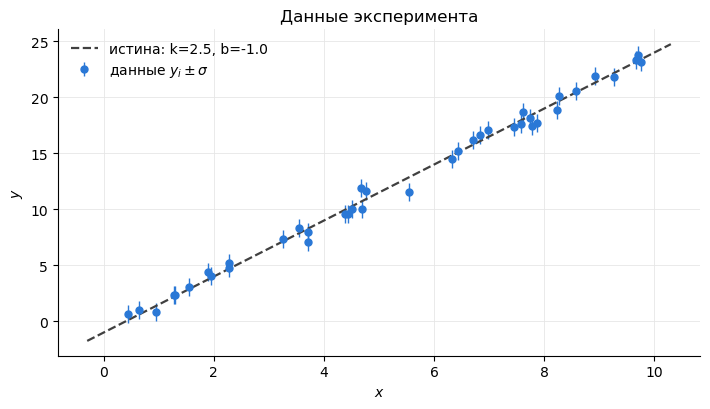

In [3]:
DATA_PNG = 'MCMC_demo_data.png'
fig, ax = plt.subplots(figsize=(7.2, 4.2))
xg = np.linspace(-0.3, 10.3, 200)
ax.errorbar(x, y, yerr=SIGMA, fmt='o', ms=5, lw=1, capsize=0, color=SERIES_COLORS[0],
            label='данные $y_i\\pm\\sigma$')
ax.plot(xg, K_TRUE*xg + B_TRUE, color='0.25', lw=1.6, ls='--', label=f'истина: k={K_TRUE}, b={B_TRUE}')
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
ax.set_title('Данные эксперимента')
ax.grid(True, color='0.9', lw=0.6)
ax.legend(frameon=False)
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
plt.tight_layout()
fig.savefig(DATA_PNG, dpi=150, bbox_inches='tight')
print('сохранено:', DATA_PNG)
plt.show()

## 2. МНК — эталон, с которым будем сравнивать

Для модели, линейной по параметрам, $\hat{\boldsymbol\beta}=(X^{\mathsf T}X)^{-1}X^{\mathsf T}y$, а
ковариация при известной $\sigma$ равна $\sigma^2(X^{\mathsf T}X)^{-1}$. Эти числа нам понадобятся
как «правильный ответ», который MCMC должен воспроизвести.

In [4]:
X = np.column_stack([x, np.ones(N)])
beta_ols = np.linalg.lstsq(X, y, rcond=None)[0]
cov_ols = SIGMA**2*np.linalg.inv(X.T @ X)
chi2_ols = np.sum((y - X @ beta_ols)**2)/SIGMA**2
print(f'МНК:      k = {beta_ols[0]:.4f} ± {np.sqrt(cov_ols[0, 0]):.4f}')
print(f'          b = {beta_ols[1]:.4f} ± {np.sqrt(cov_ols[1, 1]):.4f}')
print(f'    (корреляция k и b: {cov_ols[0, 1]/np.sqrt(cov_ols[0, 0]*cov_ols[1, 1]):+.3f})')
print(f'chi^2 = {chi2_ols:.2f} при dof = {N-2} -> chi^2/dof = {chi2_ols/(N-2):.2f}')

МНК:      k = 2.4715 ± 0.0443
          b = -0.8373 ± 0.2680
    (корреляция k и b: -0.882)
chi^2 = 20.35 при dof = 38 -> chi^2/dof = 0.54


## 3. Что мы хотим посчитать: апостериор

Байесовская формулировка:

$$p(k,b\mid\mathbf y)\;\propto\;p(\mathbf y\mid k,b)\,p(k,b),\qquad
p(\mathbf y\mid k,b)=\prod_{i=1}^{N}\frac{1}{\sqrt{2\pi}\sigma}
\exp\!\left[-\frac{(y_i-kx_i-b)^2}{2\sigma^2}\right].$$

С равномерным (плоским) приором апостериор — это просто $\exp(-\chi^2/2)$:

$$-2\ln p(k,b\mid\mathbf y)=\chi^2(k,b)+\mathrm{const},\qquad
\chi^2(k,b)=\sum_i\frac{(y_i-kx_i-b)^2}{\sigma^2}.$$

При известной $\sigma$ и плоском приоре апостериор — точное двумерное гауссово распределение с
центром в МНК-решении и ковариацией $\sigma^2(X^{\mathsf T}X)^{-1}$. Поскольку параметров всего
два, его можно посчитать **на сетке** — покажем, как оно выглядит.

сохранено: MCMC_demo_posterior.png


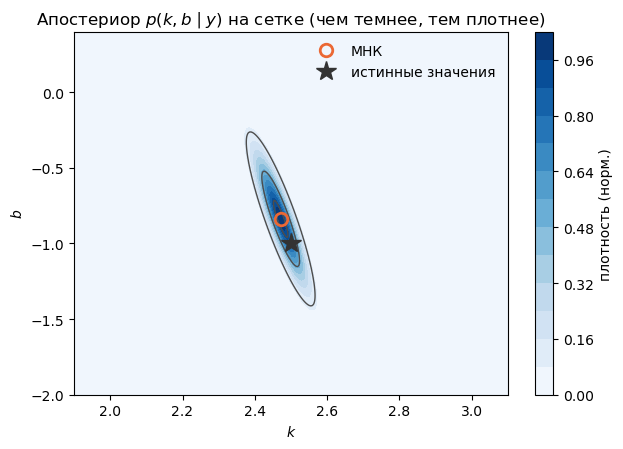

In [5]:
def chi2_map(kk, bb):
    """chi^2(k, b) на сетке."""
    return (((y[None, None, :] - kk[..., None]*x[None, None, :] - bb[..., None])**2).sum(-1)/SIGMA**2)

kk = np.linspace(1.9, 3.1, 300)
bb = np.linspace(-2.0, 0.4, 300)
KK, BB = np.meshgrid(kk, bb)
CHI = chi2_map(KK, BB)
POST = np.exp(-0.5*(CHI - CHI.min()))

POST_PNG = 'MCMC_demo_posterior.png'
fig, ax = plt.subplots(figsize=(6.4, 4.6))
cs = ax.contourf(KK, BB, POST, levels=12, cmap='Blues')
ax.contour(KK, BB, POST, levels=[0.1, 0.5, 0.9], colors='0.3', linewidths=1)
ax.plot(beta_ols[0], beta_ols[1], 'o', ms=9, mfc='none', mec=SERIES_COLORS[1], mew=2,
        label='МНК')
ax.plot(K_TRUE, B_TRUE, '*', ms=15, color='0.2', label='истинные значения')
ax.set_xlabel('$k$')
ax.set_ylabel('$b$')
ax.set_title('Апостериор $p(k,b\\mid y)$ на сетке (чем темнее, тем плотнее)')
ax.legend(frameon=False, loc='upper right')
fig.colorbar(cs, ax=ax, label='плотность (норм.)')
plt.tight_layout()
fig.savefig(POST_PNG, dpi=150, bbox_inches='tight')
print('сохранено:', POST_PNG)
plt.show()

## 4. MCMC: как это работает

**Идея.** Нужна не одна точка, а распределение. Строим случайную последовательность значений
$(k,b)$, у которой вероятность «задержаться» в области пропорциональна плотности апостериора:
тогда доля времени, проведённого в любой области, и есть вероятность этой области. Такая
последовательность — цепь Маркова, у которой апостериор является стационарным распределением.

**Алгоритм (Metropolis–Hastings, в общем виде).** Из текущей точки предлагается новая; она
принимается с вероятностью $\min\left(1, \frac{p_{\text{new}}}{p_{\text{old}}}\right)$. Плохие
точки иногда тоже принимаются — именно поэтому цепь не «скатывается» в максимум, а обходит
распределение целиком.

**Что делает `emcee`.** Это ансамблевый сэмплер: $N_w$ «ходоков» бродят одновременно, а предложение
для ходока $i$ строится как растяжение отрезка к случайному другому ходоку $j$
($\mathbf x_i\to\mathbf x_j+Z(\mathbf x_i-\mathbf x_j)$, $Z\sim$ stretch). Масштаб шага не нужно
подбирать вручную — он автоматически подстраивается под разброс ансамбля.

**Что важно контролировать:** burn-in (пока цепь «забывает» старт), время автокорреляции $\tau$
(сколько шагов между независимыми выборками) и долю принятий (0.2–0.5).

Запускаем 32 ходока из широкого прямоугольника — специально далеко от ответа, чтобы burn-in был
виден.

In [6]:
def log_like(theta):
    k, b = theta
    r = (y - (k*x + b))/SIGMA
    return -0.5*float(r @ r)

def log_prior(theta):
    k, b = theta
    if not (-2.0 < k < 7.0 and -10.0 < b < 8.0):   # плоский приор в прямоугольнике
        return -np.inf
    return 0.0

def log_prob(theta):
    lp = log_prior(theta)
    return -np.inf if not np.isfinite(lp) else lp + log_like(theta)

NWALKERS, NSTEPS, BURNIN = 32, 2000, 500
rng_mc = np.random.default_rng(SEED + 1)
p0 = np.column_stack([rng_mc.uniform(-2.0, 7.0, NWALKERS), rng_mc.uniform(-10.0, 8.0, NWALKERS)])

sampler = emcee.EnsembleSampler(NWALKERS, 2, log_prob)
sampler.run_mcmc(p0, NSTEPS, progress=False)
chain = sampler.get_chain()
print(f'цепь: {chain.shape} (шагов, ходоков, параметров)')
print(f'доля принятий: {np.mean(sampler.acceptance_fraction):.2f}')

цепь: (2000, 32, 2) (шагов, ходоков, параметров)
доля принятий: 0.71


сохранено: MCMC_demo_trace.png


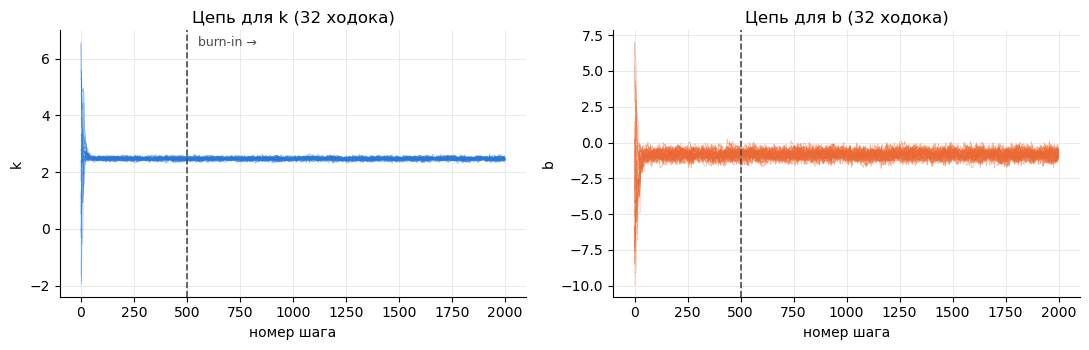

In [7]:
TRACE_PNG = 'MCMC_demo_trace.png'
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for j, (ax, name) in enumerate(zip(axes, ['k', 'b'])):
    ax.plot(chain[:, :, j], color=SERIES_COLORS[j], lw=0.5, alpha=0.45)
    ax.axvline(BURNIN, color='0.3', ls='--', lw=1.2)
    ax.set_xlabel('номер шага')
    ax.set_ylabel(name)
    ax.set_title(f'Цепь для {name} (32 ходока)')
    ax.grid(True, color='0.9', lw=0.6)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
axes[0].text(BURNIN*1.1, axes[0].get_ylim()[1]*0.92, 'burn-in →', fontsize=9, color='0.3')
plt.tight_layout()
fig.savefig(TRACE_PNG, dpi=150, bbox_inches='tight')
print('сохранено:', TRACE_PNG)
plt.show()

## 5. Сходимость и «независимые» выборки

Соседние шаги цепи коррелированы. Время автокорреляции $\tau$ — это число шагов, за которое цепь
«забывает» своё положение; независимые выборки получаются прореживанием с шагом $\sim\tau/2$.
Эффективное число независимых выборок $\approx N_{\text{шагов}}N_w/\tau$.

In [8]:
tau = sampler.get_autocorr_time(quiet=True)
thin = max(1, int(np.median(tau)/2))
flat = sampler.get_chain(discard=BURNIN, thin=thin, flat=True)
print(f'tau = {np.round(tau, 1)} шагов -> прореживаем с шагом {thin}')
print(f'выборок после burn-in и прореживания: {flat.shape[0]}')
print(f'оценка эффективного числа независимых: ~{int(np.prod(chain.shape[:2])/np.median(tau))}')

tau = [18.4 25.7] шагов -> прореживаем с шагом 11
выборок после burn-in и прореживания: 4352
оценка эффективного числа независимых: ~2900


## 6. Результат: corner-plot

Диагональ — маргинальные распределения $p(k)$ и $p(b)$ (то, что нужно для ответа), вне диагонали —
совместное распределение: видно корреляцию параметров (наклон и сдвиг «тянут» друг друга).
Пунктиром — медиана и процентили 16/50/84, звёздочкой — истинные значения.

сохранено: MCMC_demo_corner.png


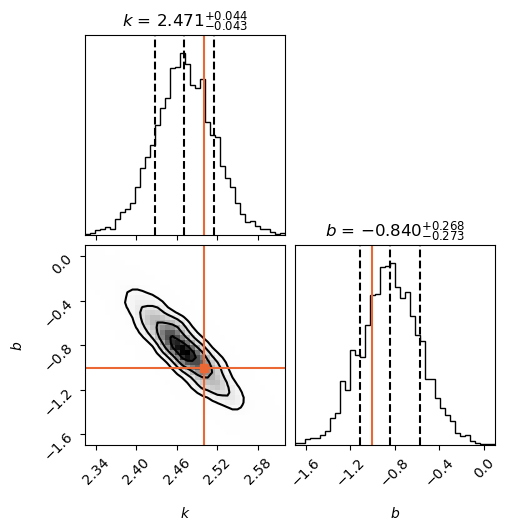

In [9]:
CORNER_PNG = 'MCMC_demo_corner.png'
fig = corner.corner(flat, labels=['$k$', '$b$'], truths=[K_TRUE, B_TRUE], truth_color=SERIES_COLORS[1],
                    quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt='.3f',
                    plot_datapoints=False, plot_density=True, smooth=True, bins=40)
fig.savefig(CORNER_PNG, dpi=150, bbox_inches='tight')
print('сохранено:', CORNER_PNG)
plt.show()

## 7. Сравнение с МНК и предсказание

При плоском приоре и известной $\sigma$ MCMC обязан воспроизвести МНК: медианы — это $\hat k,\hat b$,
а разбросы — $\sigma^2(X^{\mathsf T}X)^{-1}$. Это и есть проверка, что сэмплер работает.

Дальше — то, ради чего всё затевалось: **распределение предсказаний**. Берём много пар $(k,b)$ из
апостериора и рисуем соответствующие прямые; их разброс — честная неопределённость модели.

In [10]:
q16, q50, q84 = np.percentile(flat, [16, 50, 84], axis=0)
cmp = pd.DataFrame({
    'истина': [K_TRUE, B_TRUE],
    'МНК': [beta_ols[0], beta_ols[1]],
    'МНК, σ': [np.sqrt(cov_ols[0, 0]), np.sqrt(cov_ols[1, 1])],
    'MCMC, медиана': q50,
    'MCMC, −1σ': q50 - q16,
    'MCMC, +1σ': q84 - q50,
}, index=['k', 'b'])
cmp.round(4)

,истина,МНК,"МНК, σ","MCMC, медиана","MCMC, −1σ","MCMC, +1σ"
k,2.5,2.4715,0.0443,2.4705,0.0430,0.0441
b,-1.0,-0.8373,0.2680,-0.8399,0.2725,0.2679


сохранено: MCMC_demo_predict.png


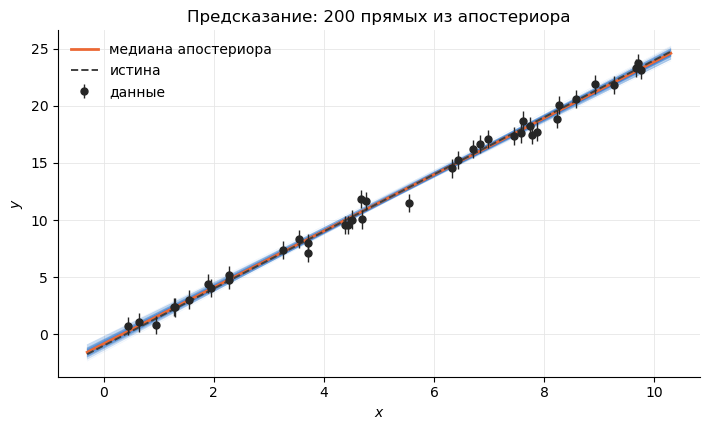

In [11]:
PRED_PNG = 'MCMC_demo_predict.png'
fig, ax = plt.subplots(figsize=(7.2, 4.4))
xg = np.linspace(-0.3, 10.3, 200)
idx = rng_mc.choice(len(flat), size=200, replace=False)
for i in idx:
    ax.plot(xg, flat[i, 0]*xg + flat[i, 1], color=SERIES_COLORS[0], lw=0.4, alpha=0.10)
ax.plot(xg, q50[0]*xg + q50[1], color=SERIES_COLORS[1], lw=2, label='медиана апостериора')
ax.plot(xg, K_TRUE*xg + B_TRUE, color='0.25', lw=1.4, ls='--', label='истина')
ax.errorbar(x, y, yerr=SIGMA, fmt='o', ms=5, lw=1, capsize=0, color='0.15', label='данные')
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
ax.set_title('Предсказание: 200 прямых из апостериора')
ax.grid(True, color='0.9', lw=0.6)
ax.legend(frameon=False, loc='upper left')
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
plt.tight_layout()
fig.savefig(PRED_PNG, dpi=150, bbox_inches='tight')
print('сохранено:', PRED_PNG)
plt.show()

## 8. Что из этого переносится на задачу определения орбиты

- **Правдоподобие** там такое же: $\chi^2$ по невязкам наблюдённых и вычисленных положений,
  поделённым на ошибку. Модель только сложнее (кеплерово движение вместо прямой).
- **Параметров больше** (6: состояние или элементы), поэтому сетка невозможна — а MCMC работает.
- **Апостериор может быть сильно вырожденным** (как для короткой 9-часовой дуги в
  `AMP_apparent_curvature5.ipynb`): тогда corner-plot показывает не аккуратный эллипс, а длинные
  «бананы» — и это честный ответ: данных не хватает, чтобы определить параметры точнее.
- **Проверка та же**: на простой модели MCMC обязан совпасть с МНК; в орбитальной задаче так же
  полезно смотреть на $\chi^2/\mathrm{dof}$ и на согласие с независимой оценкой.

Дополнительно можно потренироваться: сделать $\sigma$ третьим параметром (тогда апостериор уже
трёхмерный), поменять приор на гауссов, увеличить/уменьшить $N$ и посмотреть, как сжимается
corner-plot.